# 21.8 Multi-Head Attention

---

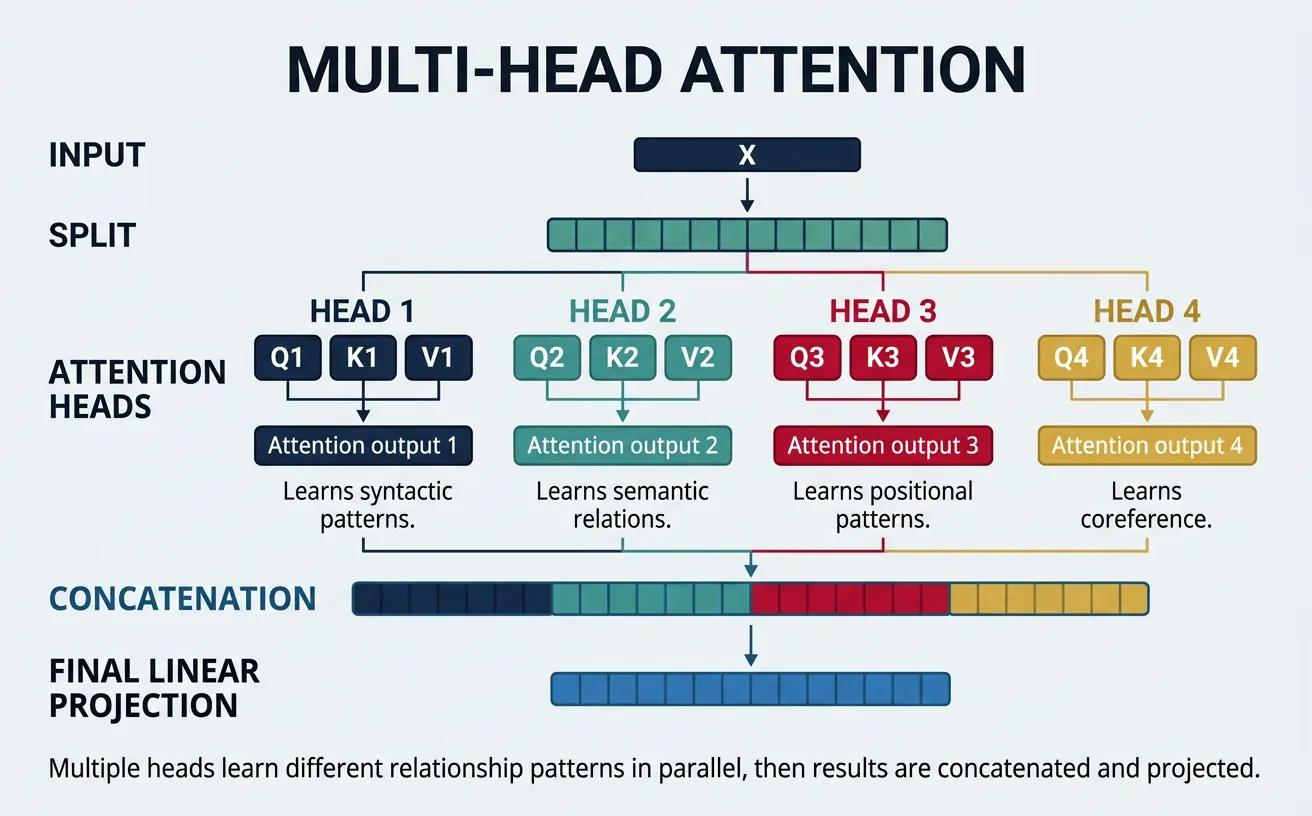

## 1. Why do we need multiple attention heads?

A single attention operation produces **one attention pattern**.

But a sentence can contain many different types of relationships simultaneously.

For example:

> **"The student gave the teacher a book because she wanted to thank her."**

Different relationships may be useful:

- **Syntactic:** `she` → `student`
- **Possessive/reference:** `her` → `teacher`
- **Semantic:** `gave` ↔ `book`
- **Local:** `a` ↔ `book`
- **Long-range:** `because` ↔ earlier clause

A single attention mechanism has to represent all of these relationships in one attention space.

**Multi-head attention allows the model to learn several attention patterns in parallel.**

> 🧠 Think of each attention head as a different "relationship detector."

---

# 2. Multiple Attention Heads

Instead of calculating attention once, Transformer calculates it **multiple times using different learned projections**.

For head \(i\):

$$
Q_i = QW_Q^{(i)}
$$

$$
K_i = KW_K^{(i)}
$$

$$
V_i = VW_V^{(i)}
$$

Then:

$$
head_i =
Attention(Q_i,K_i,V_i)
$$

where

$$
Attention(Q_i,K_i,V_i)
=
\operatorname{softmax}
\left(
\frac{Q_iK_i^T}{\sqrt{d_k}}
\right)V_i
$$

So if there are \(h\) heads:

$$
head_1,head_2,\ldots,head_h
$$

are calculated **in parallel**.

### Key idea

The heads don't share the same \(W_Q,W_K,W_V\).

Each head has its **own learned projection matrices**.

Therefore, each head can learn a different representation subspace and attention pattern.

---

# 3. Different Relationship Patterns

This is the most important intuition for NLP.

Consider:

> **"The cat sat on the mat because it was tired."**

Different heads may learn to focus on different relationships.

### Head 1 — Coreference

```text
it ───────────────→ cat
```

It may learn that **"it" refers to "cat."**

### Head 2 — Syntactic relationship

```text
sat ───→ cat
```

It may focus on the subject of the verb.

### Head 3 — Prepositional relationship

```text
on ───→ mat
```

It may capture relationships involving prepositions.

### Head 4 — Local context

```text
the ↔ mat
```

It may focus more strongly on nearby words.

These are **illustrative interpretations**, not a guarantee that every real Transformer head cleanly corresponds to one linguistic function.

The important point is:

> **Different heads have the capacity to specialize in different relationships.**

---

# 4. Why can different heads learn different patterns?

Because each head has different projection matrices.

For example:

$$
W_Q^{(1)},W_K^{(1)},W_V^{(1)}
$$

are different from:

$$
W_Q^{(2)},W_K^{(2)},W_V^{(2)}
$$

Therefore:

$$
Q_1,K_1,V_1
\neq
Q_2,K_2,V_2
$$

and consequently:

$$
Attention_1
\neq
Attention_2
$$

even though all heads receive information originating from the same input.

### Mental model

```text
                 Input
                   │
           ┌───────┼───────┐
           ↓       ↓       ↓
        Head 1   Head 2   Head 3
           │       │       │
        Pattern  Pattern  Pattern
           │       │       │
           └───────┼───────┘
                   ↓
              Concatenate
                   ↓
             Output Projection
                   ↓
                 Output
```

---

# 5. Concatenation

After every head produces its output, we combine them.

Suppose:

$$
head_1 \in \mathbb{R}^{T\times d_v}
$$

$$
head_2 \in \mathbb{R}^{T\times d_v}
$$

and we have \(h\) heads.

We concatenate them along the feature dimension:

$$
Concat(head_1,\ldots,head_h)
$$

giving:

$$
T\times(hd_v)
$$

So if:

- sequence length \(T=5\)
- number of heads \(h=8\)
- each head dimension \(d_v=64\)

then:

$$
5\times64
$$

per head becomes:

$$
5\times512
$$

after concatenation.

---

# 6. Output Projection

Concatenation isn't the final output.

We apply a learned output projection:

$$
MHA(Q,K,V)
=
Concat(head_1,\ldots,head_h)W_O
$$

where \(W_O\) is the **output projection matrix**.

If:

$$
Concat(heads)\in\mathbb{R}^{T\times hd_v}
$$

then:

$$
W_O\in\mathbb{R}^{hd_v\times d_{model}}
$$

and therefore:

$$
Output\in\mathbb{R}^{T\times d_{model}}
$$

### Why is \(W_O\) needed?

Each head independently captures information.

Concatenation simply places those representations side-by-side.

The output projection then **mixes information from all heads** and transforms it back into the model dimension.

So:

> **Heads extract different information → concatenation collects it → \(W_O\) mixes it.**

---

# 7. Complete Multi-Head Attention Equation

For each head:

$$
head_i =
Attention
(QW_Q^{(i)},
KW_K^{(i)},
VW_V^{(i)})
$$

Then:

$$
\boxed{
MHA(Q,K,V)
=
Concat(head_1,\ldots,head_h)W_O
}
$$

Substituting scaled dot-product attention:

$$
\boxed{
head_i =
\operatorname{softmax}
\left(
\frac{
(QW_Q^{(i)})
(KW_K^{(i)})^T
}{
\sqrt{d_k}
}
\right)
VW_V^{(i)}
}
$$

Then concatenate all heads and apply \(W_O\).

---

# 8. Dimension Flow — Very Important

Suppose the Transformer has:

$$
d_{model}=512
$$

and:

$$
h=8
$$

Typically:

$$
d_k=d_v=\frac{512}{8}=64
$$

Input:

$$
X\in\mathbb{R}^{T\times512}
$$

Each head projects:

$$
512\rightarrow64
$$

So:

```text
                 X
                 │
        ┌────────┼────────┐
        ↓        ↓        ↓
     Head 1    Head 2   ... Head 8
    512→64    512→64      512→64
        │        │           │
       64       64          64
        └────────┼───────────┘
                 ↓
              Concatenate
                 ↓
               8 × 64
                = 512
                 ↓
                W_O
                 512→512
                 ↓
               Output
```

This is why splitting the model dimension across heads is so useful.

---

# 9. Multi-Head Self-Attention vs Cross-Attention

The **multi-head mechanism is the same idea**; what changes is where \(Q,K,V\) originate.

### Multi-Head Self-Attention

All three originate from the same sequence:

$$
Q=XW_Q
$$

$$
K=XW_K
$$

$$
V=XW_V
$$

Used heavily in Transformer encoders and decoder self-attention.

### Multi-Head Cross-Attention

Queries come from one sequence, while keys and values come from another:

$$
Q=X_{decoder}W_Q
$$

$$
K=X_{encoder}W_K
$$

$$
V=X_{encoder}W_V
$$

Then multiple cross-attention heads operate in parallel.

So:

| | Self-Attention | Cross-Attention |
|---|---|---|
| Query | Same sequence | Decoder |
| Key | Same sequence | Encoder |
| Value | Same sequence | Encoder |
| Purpose | Build contextual representation | Retrieve information from another sequence |

---

# 10. Why This Matters for NLP

Multi-head attention is especially powerful for language because language contains **many simultaneous relationships**:

- word-to-word dependencies
- syntactic relationships
- semantic relationships
- coreference
- local context
- long-range dependencies
- source-target alignment in translation

This is one reason Transformers can represent language much more flexibly than a single attention pattern.

The original Transformer formulation explicitly describes multi-head attention as allowing the model to attend to information from different representation subspaces at different positions. 

---

# 11. Important Correction to a Common Misconception ⚠️

Don't memorize:

> "Head 1 = syntax, Head 2 = semantics, Head 3 = coreference."

That's **too rigid**.

Real attention heads don't necessarily develop clean, human-interpretable roles.

A better statement is:

> **Different heads can learn different attention patterns and representation subspaces that may capture different linguistic relationships.**

That's the technically safer interpretation.

---

# 12. The Complete Attention Pipeline

You should now be able to see the entire chain:

```text
Input representations
        │
        ├──────────────┐
        ↓              ↓
     Head 1          Head 2       ... Head h
        │              │
      Q₁K₁ᵀ          Q₂K₂ᵀ
        │              │
     Softmax         Softmax
        │              │
      × V₁            × V₂
        │              │
        └──────┬───────┘
               ↓
           Concatenate
               ↓
              W_O
               ↓
             Output
```

And mathematically:

$$
\boxed{
MHA(Q,K,V)
=
Concat
\left(
head_1,\ldots,head_h
\right)W_O
}
$$

with

$$
\boxed{
head_i=
\operatorname{softmax}
\left(
\frac{QW_Q^{(i)}
(KW_K^{(i)})^T}
{\sqrt{d_k}}
\right)
VW_V^{(i)}
}
$$

---

## 🎯 Industry / Interview Perspective

You should be able to answer:

**Why multiple heads?**

> To allow the model to attend to information from different representation subspaces and capture multiple relationships in parallel.

**Why concatenate?**

> To combine the information produced by all attention heads.

**Why output projection?**

> To mix the concatenated head representations and project them back to the model dimension.

**What is different between heads?**

> Each head has its own learned \(W_Q,W_K,W_V\) projections.

**Does each head necessarily represent one linguistic feature?**

> No. Heads may learn different patterns, but their roles are not necessarily cleanly interpretable.

---

## What you should remember 🧠

1. **Multiple heads = multiple attention operations in parallel.**
2. Each head has separate learned \(W_Q,W_K,W_V\).
3. Different heads can capture different relationships/subspaces.
4. Head outputs are **concatenated**.
5. Concatenated heads pass through the learned **output projection \(W_O\)**.
6. The core equation is:

$$
MHA(Q,K,V)=Concat(head_1,\ldots,head_h)W_O
$$

7. Multi-head attention works for both **self-attention and cross-attention**.

---